# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [65]:
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn as sk
import matplotlib.pyplot as plt

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [66]:
def mae(y_true, y_pred):
    return np.sum(np.abs(y_true-y_pred)) / len(y_true)

#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [67]:
def sse(y_true, y_pred):
    return np.sum((y_true-y_pred)**2)
    
def mse(y_true, y_pred):
    return sse(y_true, y_pred) / len(y_true)

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [68]:
def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [69]:
def mape(y_true, y_pred):
    return np.sum(np.abs((y_true - y_pred) / y_true)) * (100/len(y_true))

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [70]:
def r2(y_true, y_pred):
    sst = np.sum((y_true - np.mean(y_true))**2)
    return (sst - sse(y_true, y_pred)) / sst

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [71]:
advertisement = pd.read_csv('advertising.csv', index_col=0)
advertisement.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [72]:
X = advertisement.drop(columns='Sales')
y=advertisement['Sales']

<Axes: >

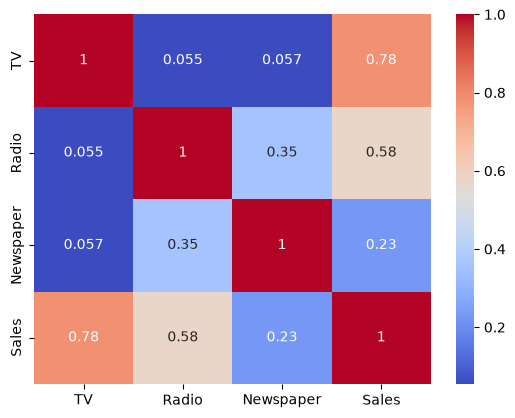

In [73]:
sns.heatmap(advertisement.corr(), annot=True, cmap='coolwarm')

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

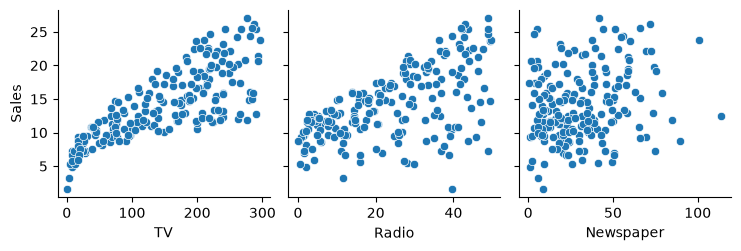

In [74]:
sns.pairplot(advertisement, x_vars=['TV', 'Radio', 'Newspaper'], y_vars='Sales')

Observations: TV correlates strongest with Sales, Radio is second and Newspaper has very weak correlation of 0.23.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [75]:
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.33, random_state=17)

scaler = sk.preprocessing.StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [76]:
model = sk.linear_model.LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print("b0:", model.intercept_)
print("b1:", model.coef_)

b0: 14.022388059701495
b1: [ 3.9675339   2.88155345 -0.07344038]


#### 2.5 Evaluate created model with above functions

In [77]:
print("MAE:", mae(y_test, y_pred))
print("SSE:", sse(y_test, y_pred))
print("MSE:", mse(y_test, y_pred))
print("RMSE:", rmse(y_test, y_pred))
print("MAPE:", mape(y_test, y_pred))
print("R2:", r2(y_test, y_pred))

MAE: 1.241490259650847
SSE: 229.19357793768404
MSE: 3.4726299687527886
RMSE: 1.8634993879131778
MAPE: 18.638804594568974
R2: 0.8515370160992793


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [78]:
scores = sk.model_selection.cross_val_score(model, X_train_scaled, y_train, cv=10, scoring='r2')
print("R2 mean:",scores.mean())

R2 mean: 0.8982698791408206


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [79]:
X2 = advertisement.drop(columns=['Newspaper', 'Sales'])
X2_train, X2_test, y2_train, y2_test = sk.model_selection.train_test_split(X2, y, test_size=0.33, random_state=17)

scaler2 = sk.preprocessing.StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

model2 = sk.linear_model.LinearRegression()
model2.fit(X2_train_scaled, y2_train)
y2_pred = model2.predict(X2_test_scaled)

In [80]:
print("MAE:", mae(y2_test, y2_pred), "Compared to previous model:", mae(y2_test, y2_pred)-mae(y_test, y_pred))
print("SSE:", sse(y2_test, y2_pred), "Compared to previous model:", sse(y2_test, y2_pred)-sse(y_test, y_pred))
print("MSE:", mse(y2_test, y2_pred), "Compared to previous model:", mse(y2_test, y2_pred)-mse(y_test, y_pred))
print("RMSE:", rmse(y2_test, y2_pred), "Compared to previous model:", rmse(y2_test, y2_pred)-rmse(y_test, y_pred))
print("MAPE:", mape(y2_test, y2_pred), "Compared to previous model:", mape(y2_test, y2_pred)-mape(y_test, y_pred))
print("R2:", r2(y2_test, y2_pred), "Compared to previous model:", r2(y2_test, y2_pred)-r2(y_test, y_pred))

MAE: 1.242361995394178 Compared to previous model: 0.0008717357433309925
SSE: 228.27690591837273 Compared to previous model: -0.9166720193113065
MSE: 3.4587409987632234 Compared to previous model: -0.013888969989565236
RMSE: 1.859769071353544 Compared to previous model: -0.0037303165596338506
MAPE: 18.594637663112877 Compared to previous model: -0.04416693145609685
R2: 0.8521308017736854 Compared to previous model: 0.0005937856744060444


Comparison: when dropped Newspaper column, almost nothing changed, meaning Newspaper has no significant value. In conclusion newer model is better due to its simplicity.

### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [81]:
lasso = sk.linear_model.Lasso(alpha=1)
lasso.fit(X_train_scaled, y_train)
print("MSE:", mse(y_test, lasso.predict(X_test_scaled)))

MSE: 4.911579294712751


#### 3.2 Ridge regression

In [82]:
ridge = sk.linear_model.Ridge(alpha=1)
ridge.fit(X_train_scaled, y_train)
print("MSE:", mse(y_test, ridge.predict(X_test_scaled)))

MSE: 3.4768894774722394


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [83]:
elasticnet = sk.linear_model.ElasticNet(alpha=1, l1_ratio=0.5)
elasticnet.fit(X_train_scaled, y_train)
print("MSE:", mse(y_test, elasticnet.predict(X_test_scaled)))

MSE: 6.843883320104107


#### 3.4 Make conclusions

Linear regression performs the best at 3.472, next to it is Ridge regression with 3.476, Lasso with 3.911 and the worst performing one was Elastic net with 6.84. Newspaper column can be dropped because it dosent bring any value.

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [84]:
def accuracy(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return (tp + tn) / (tp + tn + fp + fn)

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [85]:
def precision(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp)

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [86]:
def recall(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn)

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [87]:
def f1_score(y_true, y_pred):
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)
    return 2 * (p * r) / (p + r)

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [88]:
diabetes = pd.read_csv('diabetes.csv')

for col in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
    diabetes[col] = diabetes[col].replace(0, diabetes[col].mean())
Xd = diabetes.drop(columns='Outcome')
yd = diabetes['Outcome']
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.000000,79.799479,33.6,0.627,50,1
1,1,85.0,66.0,29.000000,79.799479,26.6,0.351,31,0
2,8,183.0,64.0,20.536458,79.799479,23.3,0.672,32,1
3,1,89.0,66.0,23.000000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.000000,168.000000,43.1,2.288,33,1


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

<Axes: >

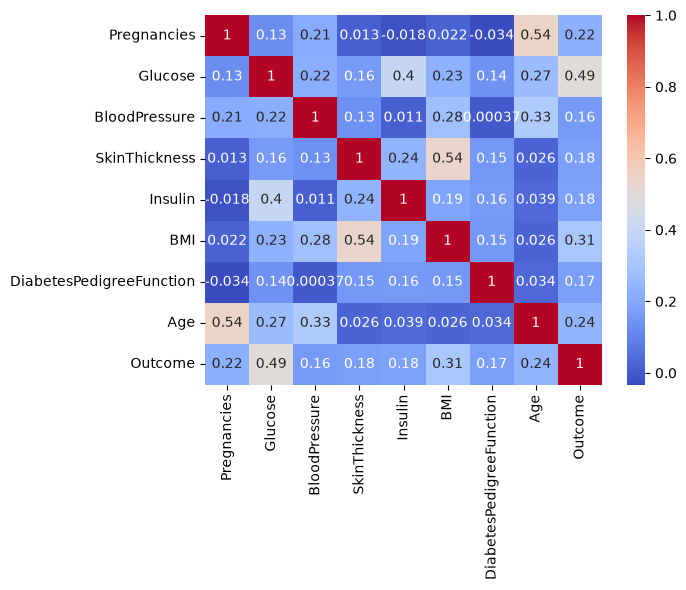

In [89]:
sns.heatmap(diabetes.corr(), annot=True, cmap='coolwarm')

Observations: Glucose has the strongest correlation with Outcome with 0.49 and next to it is BMI with 0.31.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [90]:
X_trainD, X_testD, y_trainD, y_testD = sk.model_selection.train_test_split(Xd, yd, test_size=0.33, random_state=17)

scalerD = sk.preprocessing.StandardScaler()
X_trainD_scaled = scalerD.fit_transform(X_trainD)
X_testD_scaled = scalerD.transform(X_testD)

#### 2.4 Fit logistic regression model, generate predictions

In [91]:
logreg = sk.linear_model.LogisticRegression()
logreg.fit(X_trainD_scaled, y_trainD)
y_pred_log = logreg.predict(X_testD_scaled)

#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [92]:
print(sk.metrics.confusion_matrix(y_testD, y_pred_log))

print("Accuracy:", accuracy(y_testD, y_pred_log))
print("Precision:", precision(y_testD, y_pred_log))
print("Recall:", recall(y_testD, y_pred_log))
print("F1 Score:", f1_score(y_testD, y_pred_log))

[[146  19]
 [ 41  48]]
Accuracy: 0.7637795275590551
Precision: 0.7164179104477612
Recall: 0.5393258426966292
F1 Score: 0.6153846153846154


#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

Area under the curve: 0.8332311882873681


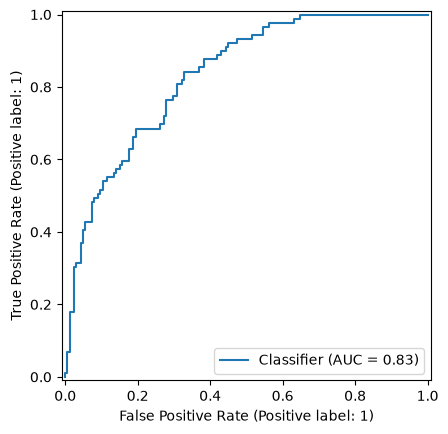

In [93]:
y_proba_log = logreg.predict_proba(X_testD_scaled)[:, 1]
print("Area under the curve:", sk.metrics.roc_auc_score(y_testD, y_proba_log))

sk.metrics.RocCurveDisplay.from_predictions(y_testD, y_proba_log)

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [94]:
scores = sk.model_selection.cross_val_score(sk.linear_model.LogisticRegression(), X_trainD_scaled, y_trainD, cv=10, scoring='accuracy')
print("Mean accuracy:", scores.mean())

Mean accuracy: 0.768552036199095


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [95]:
tree_clf = sk.tree.DecisionTreeClassifier(random_state=17)
tree_clf.fit(X_trainD_scaled, y_trainD)
y_pred_tree = tree_clf.predict(X_testD_scaled)

#### 3.2 Evaluate created model with above functions

In [96]:
print(sk.metrics.confusion_matrix(y_testD, y_pred_tree))

print("Accuracy:", accuracy(y_testD, y_pred_tree))
print("Precision:", precision(y_testD, y_pred_tree))
print("Recall:", recall(y_testD, y_pred_tree))
print("F1 Score:", f1_score(y_testD, y_pred_tree))

[[128  37]
 [ 26  63]]
Accuracy: 0.7519685039370079
Precision: 0.63
Recall: 0.7078651685393258
F1 Score: 0.6666666666666666


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

Area under the curve: 0.7418113721484507


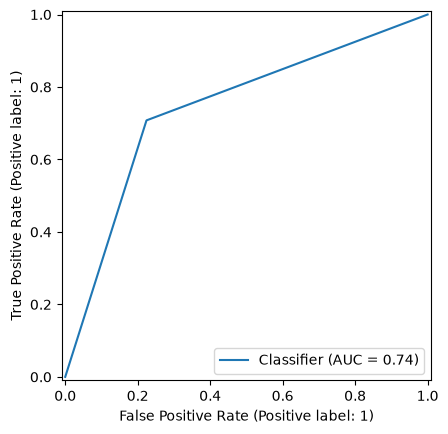

In [97]:
y_proba_tree = tree_clf.predict_proba(X_testD_scaled)[:, 1]
print("Area under the curve:", sk.metrics.roc_auc_score(y_testD, y_proba_tree))
sk.metrics.RocCurveDisplay.from_predictions(y_testD, y_proba_tree)

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [98]:
scores = sk.model_selection.cross_val_score(sk.tree.DecisionTreeClassifier(random_state=17), X_trainD_scaled, y_trainD, cv=10, scoring='accuracy')
print("Mean accuracy:", scores.mean())

Mean accuracy: 0.7083333333333334


#### 3.5 Make conclusions

Logistic regression is better than the decision tree by a bit accuracy 0.76 vs 0.75, AUC 0.83 vs 0.74. However Tree has higher recall 0.71 vs 0.54, but it overfits data that we can see from lower k-fold-cross-validation accuracy.